
# Price Optimization

Develop a data science pipeline for pricing and distribution
of avocados to maximize revenue.

<div class="alert alert-info"><h4>Note</h4><p>This example is adapted from the example in Gurobi’s modeling
   examples [How Much Is Too Much? Avocado Pricing and Supply Using
   Mathematical
   Optimization](https://github.com/Gurobi/modeling-examples/tree/master/price_optimization)_.

   The main difference is that it uses ``Scikit-learn`` for the
   regression model and Gurobi Machine Learning to formulate the regression
   in a Gurobi model.

   But it also differs in that it uses Matrix variables and that the
   interactive part of the notebook is skipped. Please refer to the
   original example for this.

   This example illustrates in particular how to use categorical
   variables in a regression.

   If you are already familiar with the example from the other notebook,
   you can jump directly to [building the regression
   model](#Part-II:-Predict-the-Sales)_ and then to [formulating the
   optimization
   problem](#Part-III:-Optimize-for-Price-and-Supply-of-Avocados)_.</p></div>

A [Food Network
article](https://www.foodnetwork.com/fn-dish/news/2018/3/avocado-unseats-banana-as-america-s-top-fruit-import-by-value)_
from March 2017 declared, “Avocado unseats banana as America’s top fruit
import.” This declaration is incomplete and debatable for reasons other
than whether avocado is a fruit. Avocados are expensive.

As a supplier, setting an appropriate avocado price requires a delicate
trade-off. Set it too high and you lose customers. Set it too low, and
you won’t make a profit. Equipped with good data, the avocado pricing
and supply problem is *ripe* with opportunities for demonstrating the
power of optimization and data science.

They say when life gives you avocados, make guacamole. Just like the
perfect guacamole needs the right blend of onion, lemon and spices,
finding an optimal avocado price needs the right blend of descriptive,
predictive and prescriptive analytics.


This notebook walks through a decision-making pipeline that culminates
in a mathematical optimization model. There are three stages:

-  First, understand the dataset and infer the relationships between
   categories such as the sales, price, region, and seasonal trends.
-  Second, build a prediction model that predicts the demand for
   avocados as a function of price, region, year and the seasonality.
-  Third, design an optimization problem that sets the optimal price and
   supply quantity to maximize the net revenue while incorporating costs
   for wastage and transportation.


## Load the Packages and the Datasets

We use real sales data provided by the [Hass Avocado
Board](https://hassavocadoboard.com/)_ (HAB), whose aim is to “make
avocados America’s most popular fruit”. This dataset contains
consolidated information on several years’ worth of market prices and
sales of avocados.

We will now load the following packages for analyzing and visualizing
the data.




In [1]:
import gurobipy as gp
import gurobipy_pandas as gppd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import make_column_transformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from gurobi_ml import add_predictor_constr

The dataset from HAB contains sales data for the years 2019-2022. This
data is augmented by a previous download from HAB available on
[Kaggle](https://www.kaggle.com/datasets/timmate/avocado-prices-2020)_
with sales for the years 2015-2018.

Each row in the dataset is the weekly number of avocados sold and the
weekly average price of an avocado categorized by region and type of
avocado. There are two types of avocados: conventional and organic. In
this notebook, we will only consider the conventional avocados. There
are eight large regions, namely the Great Lakes, Midsouth, North East,
Northern New England, South Central, South East, West and Plains.

Now, load the data and store into a Pandas dataframe.




In [2]:
data_url = "https://raw.githubusercontent.com/Gurobi/modeling-examples/master/price_optimization/"
avocado = pd.read_csv(
    data_url + "HABdata_2019_2022.csv"
)  # dataset downloaded directly from HAB
avocado_old = pd.read_csv(
    data_url + "kaggledata_till2018.csv"
)  # dataset downloaded from Kaggle

# The date is in different formats in the two data sets and
# need to be converted separately
avocado["date"] = pd.to_datetime(avocado["date"], format="%m/%d/%y %H:%M")
avocado_old["date"] = pd.to_datetime(avocado_old["date"], format="%m/%d/%y")

# Concatenate the two notebooks
avocado = pd.concat([avocado, avocado_old])
avocado

,region,date,type,price,units_sold
0,Great_Lakes,2019-01-07,Conventional,1.106743,3812441.96
1,Great_Lakes,2019-01-07,Organic,1.371280,275987.52
2,Great_Lakes,2019-01-13,Conventional,1.063457,3843318.68
3,Great_Lakes,2019-01-13,Organic,1.493384,244991.95
4,Great_Lakes,2019-01-20,Conventional,1.049931,4587957.69
...,...,...,...,...,...
3703,West,2018-11-18,Organic,1.610000,334096.14
3704,West,2018-11-25,Conventional,1.240000,3260102.17
3705,West,2018-11-25,Organic,1.730000,268362.34
3706,West,2018-12-02,Conventional,1.200000,4594863.86


## Prepare the Dataset

We will now prepare the data for making sales predictions. Add new
columns to the dataframe for the year and seasonality. Let each year
from 2015 through 2022 be given an index from 0 through 7 in the
increasing order of the year. We will define the peak season to be the
months of February through July. These months are set based on visual
inspection of the trends, but you can try setting other months.




In [3]:
# Add the index for each year from 2015 through 2022
avocado["year"] = pd.DatetimeIndex(avocado["date"]).year
avocado = avocado.sort_values(by="date")

# Define the peak season
avocado["month"] = pd.DatetimeIndex(avocado["date"]).month
peak_months = range(2, 8)  # <--------- Set the months for the "peak season"


def peak_season(row):
    return 1 if int(row["month"]) in peak_months else 0


avocado["peak"] = avocado.apply(lambda row: peak_season(row), axis=1)

# Scale the number of avocados to millions
avocado["units_sold"] = avocado["units_sold"] / 1000000

# Select only conventional avocados
avocado = avocado[avocado["type"] == "Conventional"]

avocado = avocado[
    ["date", "units_sold", "price", "region", "year", "month", "peak"]
].reset_index(drop=True)

avocado

,date,units_sold,price,region,year,month,peak
0,2015-01-04,3.382800,1.020000,Great_Lakes,2015,1,0
1,2015-01-04,2.578275,1.100000,Midsouth,2015,1,0
2,2015-01-04,5.794411,0.890000,West,2015,1,0
3,2015-01-04,3.204112,0.980000,Southeast,2015,1,0
4,2015-01-04,0.321824,1.050000,Northern_New_England,2015,1,0
...,...,...,...,...,...,...,...
3397,2022-05-15,4.150433,1.269883,SouthCentral,2022,5,1
3398,2022-05-15,4.668815,1.644873,Northeast,2022,5,1
3399,2022-05-15,32.745321,1.527357,Total_US,2022,5,1
3400,2022-05-15,3.542902,1.514583,Midsouth,2022,5,1


## Part 1: Observe Trends in the Data

Now, we will infer sales trends in time and seasonality. For simplicity,
let’s proceed with data from the United States as a whole.




In [4]:
df_Total_US = avocado[avocado["region"] == "Total_US"]

### Sales Over the Years




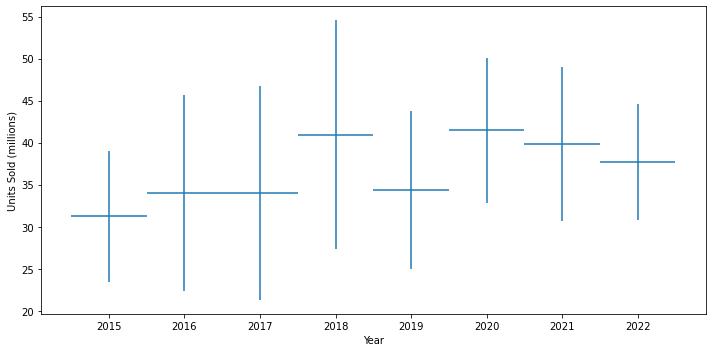

In [5]:
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(10, 5))

mean = df_Total_US.groupby("year")["units_sold"].mean()
std = df_Total_US.groupby("year")["units_sold"].std()
axes.errorbar(mean.index, mean, xerr=0.5, yerr=2 * std, linestyle="")
axes.set_ylabel("Units Sold (millions)")
axes.set_xlabel("Year")

fig.tight_layout()

We can see that the sales generally increased over the years, albeit
marginally. The dip in 2019 is the effect of the well-documented [2019
avocado
shortage](https://abc7news.com/avocado-shortage-season-prices/5389855/)_
that led to avocados [nearly doubling in
price.](https://abc7news.com/avocado-shortage-season-prices/5389855/)_




### Seasonality

We will now see the sales trends within a year.




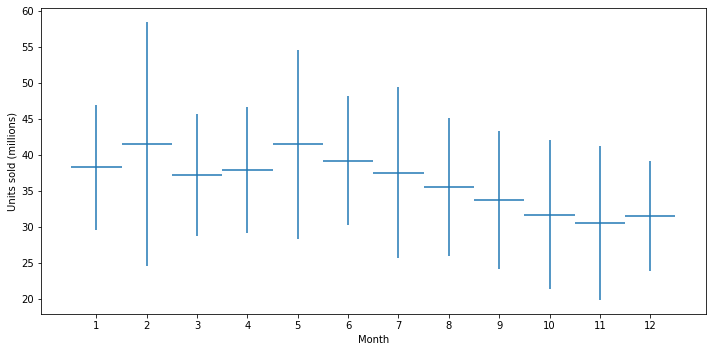

In [6]:
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(10, 5))

mean = df_Total_US.groupby("month")["units_sold"].mean()
std = df_Total_US.groupby("month")["units_sold"].std()

axes.errorbar(mean.index, mean, xerr=0.5, yerr=2 * std, linestyle="")
axes.set_ylabel("Units Sold (millions)")
axes.set_xlabel("Month")

fig.tight_layout()

plt.xlabel("Month")
axes.set_xticks(range(1, 13))
plt.ylabel("Units sold (millions)")
plt.show()

We see a Super Bowl peak in February and a Cinco de Mayo peak in May.




### Correlations

Now, we will see how the variables are correlated with each other. The
end goal is to predict sales given the price of an avocado, year and
seasonality (peak or not).




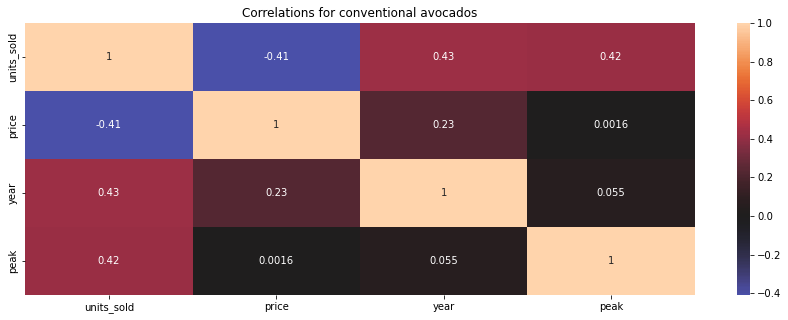

In [7]:
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(15, 5))
sns.heatmap(
    df_Total_US[["units_sold", "price", "year", "peak"]].corr(),
    annot=True,
    center=0,
    ax=axes,
)

axes.set_title("Correlations for conventional avocados")
plt.show()

As expected, the sales quantity has a negative correlation with the
price per avocado. The sales quantity has a positive correlation with
the year and season being a peak season.




### Regions

Finally, we will see how the sales differ among the different regions.
This will determine the number of avocados that we want to supply to
each region.




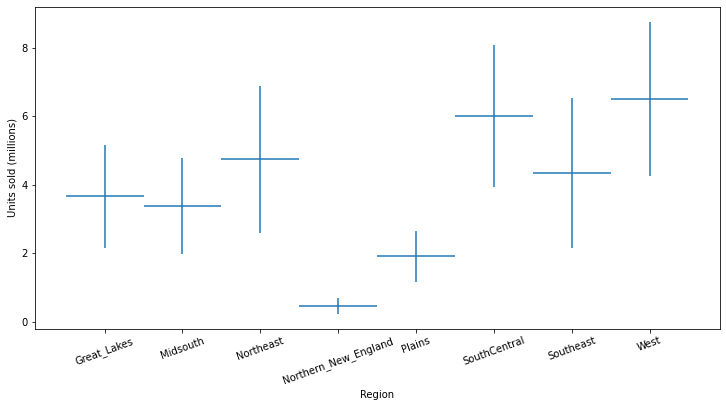

In [8]:
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(10, 5))

regions = [
    "Great_Lakes",
    "Midsouth",
    "Northeast",
    "Northern_New_England",
    "SouthCentral",
    "Southeast",
    "West",
    "Plains",
]
df = avocado[avocado.region.isin(regions)]

mean = df.groupby("region")["units_sold"].mean()
std = df.groupby("region")["units_sold"].std()

axes.errorbar(range(len(mean)), mean, xerr=0.5, yerr=2 * std, linestyle="")

fig.tight_layout()

plt.xlabel("Region")
plt.xticks(range(len(mean)), pd.DataFrame(mean)["units_sold"].index, rotation=20)
plt.ylabel("Units sold (millions)")
plt.show()

Clearly, west-coasters love avocados.




## Part II: Predict the Sales

The trends observed in Part I motivate us to construct a prediction
model for sales using the independent variables- price, year, region and
seasonality. Henceforth, the sales quantity will be referred to as the
*predicted demand*.




To validate the regression model, we will randomly split the dataset
into $80\%$ training and $20\%$ testing data and learn the
weights using ``Scikit-learn``.




In [9]:
X = df[["region", "price", "year", "peak"]]
y = df["units_sold"]
# Split the data for training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.8, random_state=1
)

Note that the region is a categorical variable.

To apply a linear regression, we need to transform those variable using
an encoding. Here we use Scikit Learn ``OneHotEncoder``. We also use a
standard scaler for prices and year index. All those transformations are
combined with a ``Column Transformer`` built using
``make_column_transformer``.




In [10]:
feat_transform = make_column_transformer(
    (OneHotEncoder(drop="first"), ["region"]),
    (StandardScaler(), ["price", "year"]),
    ("passthrough", ["peak"]),
    verbose_feature_names_out=False,
    remainder="drop",
)

The regression model is a pipeline consisting of the
``Column Transformer`` we just defined and a Linear Regression.

Define it and train it.




In [11]:
lin_reg = make_pipeline(feat_transform, LinearRegression())
lin_reg.fit(X_train, y_train)

# Get R^2 from test data
y_pred = lin_reg.predict(X_test)
print(f"The R^2 value in the test set is {r2_score(y_test, y_pred)}")

The R^2 value in the test set is 0.8982069358257863


We can observe a good $R^2$ value in the test set. We will now
train the fit the weights to the full dataset.




In [12]:
lin_reg.fit(X, y)

y_pred_full = lin_reg.predict(X)
print(f"The R^2 value in the full dataset is {r2_score(y, y_pred_full)}")

The R^2 value in the full dataset is 0.9066729322212483


## Part III: Optimize for Price and Supply of Avocados




Knowing how the price of an avocado affects the demand, how can we set
the optimal avocado price? We don’t want to set the price too high,
since that could drive demand and sales down. At the same time, setting
the price too low could be suboptimal when maximizing revenue. So what
is the sweet spot?

On the distribution logistics, we want to make sure that there are
enough avocados across the regions. We can address these considerations
in a mathematical optimization model. An optimization model finds the
**best solution** according to an **objective function** such that the
solution satisfies a set of **constraints**. Here, a solution is
expressed as a vector of real values or integer values called **decision
variables**. Constraints are a set of equations or inequalities written
as a function of the decision variables.

At the start of each week, assume that the total number of available
products is finite. This quantity needs to be distributed to the various
regions while maximizing net revenue. So there are two key decisions -
the price of an avocado in each region, and the number of avocados
allocated to each region.

Let us now define some input parameters and notations used for creating
the model. The subscript $r$ will be used to denote each region.

### Input Parameters

-  $R$: set of regions,
-  $d(p,r)$: predicted demand in region $r\in R$ when the
   avocado per product is $p$,
-  $B$: available avocados to be distributed across the regions,
-  $c_{waste}$: cost ($\$$) per wasted avocado,
-  $c^r_{transport}$: cost ($\$$) of transporting a avocado
   to region $r \in R$,
-  $a^r_{min},a^r_{max}$: minimum and maximum price ($\$$)
   per avocado for reigon $r \in R$,
-  $b^r_{min},b^r_{max}$: minimum and maximum number of avocados
   allocated to region $r \in R$,

The following code loads the Gurobi python package and initiates the
optimization model. The value of $B$ is set to $30$ million
avocados, which is close to the average weekly supply value from the
data. For illustration, let us consider the peak season of 2021. The
cost of wasting an avocado is set to $\$0.10$. The cost of
transporting an avocado ranges between $\$0.10$ to $\$0.50$
based on each region’s distance from the southern border, where the
[majority of avocado supply comes
from](https://www.britannica.com/plant/avocado)_. Further, we can set
the price of an avocado to not exceed $\$ 2$ apiece.




In [13]:
# Sets and parameters
B = 30  # total amount ot avocado supply

peak_or_not = 1  # 1 if it is the peak season; 1 if isn't
year = 2022

c_waste = 0.1  # the cost ($) of wasting an avocado

# the cost of transporting an avocado
c_transport = pd.Series(
    {
        "Great_Lakes": 0.3,
        "Midsouth": 0.1,
        "Northeast": 0.4,
        "Northern_New_England": 0.5,
        "SouthCentral": 0.3,
        "Southeast": 0.2,
        "West": 0.2,
        "Plains": 0.2,
    },
    name="transport_cost",
)

c_transport = c_transport.loc[regions]
# the cost of transporting an avocado

# Get the lower and upper bounds from the dataset for the price and the number of products to be stocked
a_min = 0  # minimum avocado price in each region
a_max = 2  # maximum avocado price in each region

data = pd.concat(
    [
        c_transport,
        df.groupby("region")["units_sold"].min().rename("min_delivery"),
        df.groupby("region")["units_sold"].max().rename("max_delivery"),
    ],
    axis=1,
)

data

,transport_cost,min_delivery,max_delivery
Great_Lakes,0.3,2.063574,7.094765
Midsouth,0.1,1.845443,6.168572
Northeast,0.4,2.364424,8.836406
Northern_New_England,0.5,0.219690,0.917984
SouthCentral,0.3,3.687130,10.323175
Southeast,0.2,2.197764,7.810475
West,0.2,3.260102,11.274749
Plains,0.2,1.058938,3.575499


### Decision Variables

Let us now define the decision variables. In our model, we want to store
the price and number of avocados allocated to each region. We also want
variables that track how many avocados are predicted to be sold and how
many are predicted to be wasted. The following notation is used to model
these decision variables.

$p$ the price of an avocado ($\$$) in each region,

$x$ the number of avocados supplied to each region,

$s$ the predicted number of avocados sold in each region,

$w$ the predicted number of avocados wasted in each region.

$d$ the predicted demand in each region.

All those variables are created using gurobipy-pandas, with the function
``gppd.add_vars`` they are given the same index as the ``data``
dataframe.




In [14]:
m = gp.Model("Avocado_Price_Allocation")

p = gppd.add_vars(m, data, name="price", lb=a_min, ub=a_max)
x = gppd.add_vars(m, data, name="x", lb="min_delivery", ub="max_delivery")
s = gppd.add_vars(
    m, data, name="s"
)  # predicted amount of sales in each region for the given price).
w = gppd.add_vars(m, data, name="w")  # excess wasteage in each region).
d = gppd.add_vars(
    m, data, lb=-gp.GRB.INFINITY, name="demand"
)  # Add variables for the regression

m.update()

# Display one of the variables
p

Set parameter Username
Academic license - for non-commercial use only - expires 2026-02-19


Great_Lakes                      <gurobi.Var price[Great_Lakes]>
Midsouth                            <gurobi.Var price[Midsouth]>
Northeast                          <gurobi.Var price[Northeast]>
Northern_New_England    <gurobi.Var price[Northern_New_England]>
SouthCentral                    <gurobi.Var price[SouthCentral]>
Southeast                          <gurobi.Var price[Southeast]>
West                                    <gurobi.Var price[West]>
Plains                                <gurobi.Var price[Plains]>
Name: price, dtype: object

### Set the Objective

Next, we will define the objective function: we want to maximize the
**net revenue**. The revenue from sales in each region is calculated by
the price of an avocado in that region multiplied by the quantity sold
there. There are two types of costs incurred: the wastage costs for
excess unsold avocados and the cost of transporting the avocados to the
different regions.

The net revenue is the sales revenue subtracted by the total costs
incurred. We assume that the purchase costs are fixed and are not
incorporated in this model.

Using the defined decision variables, the objective can be written as
follows.

$\max \sum_{r}  (p_r * s_r - c_{waste} * w_r - c^r_{transport} * x_r)$

Let us now add the objective function to the model.




In [15]:
m.setObjective(
    (p * s).sum() - c_waste * w.sum() - (c_transport * x).sum(), gp.GRB.MAXIMIZE
)

### Add the Supply Constraint

We now introduce the constraints. The first constraint is to make sure
that the total number of avocados supplied is equal to $B$, which
can be mathematically expressed as follows.

$\sum_{r} x_r = B$

The following code adds this constraint to the model.




In [16]:
m.addConstr(x.sum() == B)
m.update()

### Add Constraints That Define Sales Quantity

Next, we should define the predicted sales quantity in each region. We
can assume that if we supply more than the predicted demand, we sell
exactly the predicted demand. Otherwise, we sell exactly the allocated
amount. Hence, the predicted sales quantity is the minimum of the
allocated quantity and the predicted demand, i.e.,
$s_r = \min \{x_r,d_r(p_r)\}$. This relationship can be modeled by
the following two constraints for each region $r$.

$
\begin{align} s_r &\leq x_r  \\
s_r &\leq d(p_r,r) 
\end{align}
$

These constraints will ensure that the sales quantity $s_r$ in
region $r$ is greater than neither the allocated quantity nor the
predicted demand. Note that the maximization objective function tries to
maximize the revenue from sales, and therefore the optimizer will
maximize the predicted sales quantity. This is assuming that the surplus
and transportation costs are less than the sales price per avocado.
Hence, these constraints along with the objective will ensure that the
sales are equal to the minimum of supply and predicted demand.

Let us now add these constraints to the model.

In this case, we use gurobipy-pandas, add_constrs function




In [17]:
gppd.add_constrs(m, s, gp.GRB.LESS_EQUAL, x)
gppd.add_constrs(m, s, gp.GRB.LESS_EQUAL, d)
m.update()

### Add the Wastage Constraints

Finally, we should define the predicted wastage in each region, given by
the supplied quantity that is not predicted to be sold. We can express
this mathematically for each region $r$.

$w_r = x_r - s_r$

We can add these constraints to the model.




In [18]:
gppd.add_constrs(m, w, gp.GRB.EQUAL, x - s)
m.update()

### Add the constraints to predict demand




First, we create our input for the predictor constraint.

The dataframe ``feats`` will contain features that are fixed:

-  ``year``
-  ``peak`` with the value of ``peak_or_not``
-  ``region`` that repeat the names of the regions.

and the price variable ``p``.

It is indexed by the regions (we predict the demand independently for
each region).

Display the dataframe to make sure it is correct




In [19]:
feats = pd.DataFrame(
    data={
        "region": regions,
        "price": p,
        "year": year,
        "peak": peak_or_not,
    },
    index=regions,
)
feats

,region,price,year,peak
Great_Lakes,Great_Lakes,<gurobi.Var price[Great_Lakes]>,2022,1
Midsouth,Midsouth,<gurobi.Var price[Midsouth]>,2022,1
Northeast,Northeast,<gurobi.Var price[Northeast]>,2022,1
Northern_New_England,Northern_New_England,<gurobi.Var price[Northern_New_England]>,2022,1
SouthCentral,SouthCentral,<gurobi.Var price[SouthCentral]>,2022,1
Southeast,Southeast,<gurobi.Var price[Southeast]>,2022,1
West,West,<gurobi.Var price[West]>,2022,1
Plains,Plains,<gurobi.Var price[Plains]>,2022,1


Now, we just need to call
[add_predictor_constr](../auto_generated/gurobi_ml.add_predictor_constr.rst)_
to insert the constraints linking the features and the demand.




In [20]:
pred_constr = add_predictor_constr(m, lin_reg, feats, d)

pred_constr.print_stats()

Model for pipe:
88 variables
24 constraints
Input has shape (8, 4)
Output has shape (8, 1)

Pipeline has 2 steps:

--------------------------------------------------------------------------------
Step            Output Shape    Variables              Constraints              
                                                Linear    Quadratic      General
col_trans            (8, 10)           24           16            0            0

lin_reg               (8, 1)           64            8            0            0

--------------------------------------------------------------------------------


### Fire Up the Solver

We have added the decision variables, objective function, and the
constraints to the model. The model is ready to be solved. Before we do
so, we should let the solver know what type of model this is. The
default setting assumes that the objective and the constraints are
linear functions of the variables.

In our model, the objective is **quadratic** since we take the product
of price and the predicted sales, both of which are variables.
Maximizing a quadratic term is said to be **non-convex**, and we specify
this by setting the value of the [Gurobi NonConvex
parameter](https://www.gurobi.com/documentation/9.5/refman/nonconvex.html)_
to be $2$.




In [21]:
m.Params.NonConvex = 2
m.optimize()

Set parameter NonConvex to value 2
Gurobi Optimizer version 12.0.1 build v12.0.1rc0 (linux64 - "Ubuntu 22.04.5 LTS")

CPU model: Intel(R) Core(TM) i5-1035G1 CPU @ 1.00GHz, instruction set [SSE2|AVX|AVX2|AVX512]
Thread count: 4 physical cores, 8 logical processors, using up to 8 threads

Non-default parameters:
NonConvex  2

Optimize a model with 49 rows, 128 columns and 184 nonzeros
Model fingerprint: 0x6fde2eb4
Model has 8 quadratic objective terms
Coefficient statistics:
  Matrix range     [2e-01, 3e+00]
  Objective range  [1e-01, 5e-01]
  QObjective range [2e+00, 2e+00]
  Bounds range     [2e-01, 2e+03]
  RHS range        [1e+00, 2e+03]
Presolve removed 24 rows and 96 columns

Continuous model is non-convex -- solving as a MIP

Presolve removed 32 rows and 104 columns
Presolve time: 0.00s
Presolved: 34 rows, 34 columns, 81 nonzeros
Presolved model has 8 bilinear constraint(s)
Variable types: 34 continuous, 0 integer (0 binary)
Found heuristic solution: objective 42.5082914

Root rel

The solver solved the optimization problem in less than a second. Let us
now analyze the optimal solution by storing it in a Pandas dataframe.




In [22]:
solution = pd.DataFrame(index=regions)

solution["Price"] = p.gppd.X
solution["Allocated"] = x.gppd.X
solution["Sold"] = s.gppd.X
solution["Wasted"] = w.gppd.X
solution["Pred_demand"] = d.gppd.X

opt_revenue = m.ObjVal
print("\n The optimal net revenue: $%f million" % opt_revenue)
solution.round(4)


 The optimal net revenue: $42.508291 million


,Price,Allocated,Sold,Wasted,Pred_demand
Great_Lakes,1.6639,3.4464,3.4464,0.0000,3.4464
Midsouth,1.5088,5.2723,3.5454,1.7268,3.5454
Northeast,2.0000,4.1387,4.1387,0.0000,4.1387
Northern_New_England,1.4412,0.9180,0.9180,0.0000,0.9180
SouthCentral,2.0000,4.4195,4.4195,0.0000,4.4195
Southeast,1.7464,3.8486,3.8486,0.0000,3.8486
West,2.0000,5.3075,5.3075,0.0000,5.3075
Plains,1.2021,2.6491,2.6491,0.0000,2.6491


We can also check the error in the estimate of the Gurobi solution for
the regression model.




In [23]:
print(
    "Maximum error in approximating the regression {:.6}".format(
        np.max(pred_constr.get_error())
    )
)

Maximum error in approximating the regression 1.77636e-15


And the computed features of the regression model in a pandas dataframe.




In [24]:
pred_constr.input_values.drop("region", axis=1)

,price,year,peak
Great_Lakes,1.663872,2022,1
Midsouth,1.508809,2022,1
Northeast,2.0,2022,1
Northern_New_England,1.441157,2022,1
SouthCentral,2.0,2022,1
Southeast,1.74637,2022,1
West,2.0,2022,1
Plains,1.20207,2022,1


Let us now visualize a scatter plot between the price and the number of
avocados sold (in millions) for the eight regions.




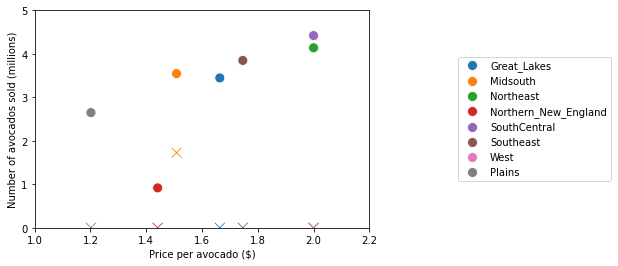

The circles represent sales quantity and the cross markers represent the wasted quantity.


In [25]:
fig, ax = plt.subplots(1, 1)

plot_sol = sns.scatterplot(
    data=solution, x="Price", y="Sold", hue=solution.index, s=100
)
plot_waste = sns.scatterplot(
    data=solution,
    x="Price",
    y="Wasted",
    marker="x",
    hue=solution.index,
    s=100,
    legend=False,
)

plot_sol.legend(loc="center left", bbox_to_anchor=(1.25, 0.5), ncol=1)
plot_waste.legend(loc="center left", bbox_to_anchor=(1.25, 0.5), ncol=1)
plt.ylim(0, 5)
plt.xlim(1, 2.2)
ax.set_xlabel("Price per avocado ($)")
ax.set_ylabel("Number of avocados sold (millions)")
plt.show()
print(
    "The circles represent sales quantity and the cross markers represent the wasted quantity."
)

We have shown how to model the price and supply optimization problem
with Gurobi Machine Learning. In the [Gurobi modeling examples
notebook](https://github.com/Gurobi/modeling-examples/tree/master/price_optimization)_
more analysis of the solutions this model can give is done
interactively. Be sure to take look at it.




Copyright © 2023 Gurobi Optimization, LLC


